# K-Nearest Neighbors Classifier

**Review 2 - Classification Part A - target: transmission**

This project-native rerun uses the same balanced 2,500-row UK dataset, fixed 80:20 split,
feature engineering and fold-safe preprocessing as every other classifier in TORQUEX.
The original Review 1 score is not reused. Part A keeps the established baseline settings;
five-fold cross-validation evaluates the model but does not tune it.

## 1. Imports

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook inside the project or project/notebooks folder.")
sys.path.insert(0, str(ROOT))

from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import GridSearchCV, cross_validate
import joblib

from src.classification import *


## 2. Dataset audit, target definition and preprocessing

In [2]:
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]

display(
    pd.DataFrame(
        {
            "Raw": raw[TARGET].value_counts(),
            "Cleaned": df[TARGET].value_counts(),
            "Train": y_train.value_counts(),
            "Test": y_test.value_counts(),
        }
    )
)
display(df.dtypes.to_frame("dtype").astype(str))
print("Raw shape:", raw.shape)
print("Cleaned shape:", df.shape)
print("Removed exact duplicate rows:", len(raw) - len(df))
print("Training rows:", len(train), "| Held-out test rows:", len(test))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Raw shape: (2500, 10)
Cleaned shape: (2500, 10)
Removed exact duplicate rows: 0
Training rows: 2000 | Held-out test rows: 500


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


## 3. Required EDA

Cleaned shape: (2500, 10) | Training: 2000 | Test: 500
Missing training values:
 brand            0
model            0
year             0
price_gbp        0
mileage_miles    0
fuel_type        0
tax_gbp          0
mpg_uk           0
engine_size_l    0
transmission     0
Training IQR outlier counts (retained; log transforms reduce skew):
car_age           38
log_price         22
log_mileage       74
tax_gbp          642
mpg_uk            20
engine_size_l    147


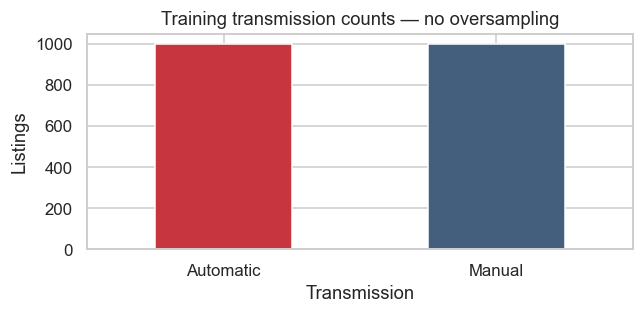

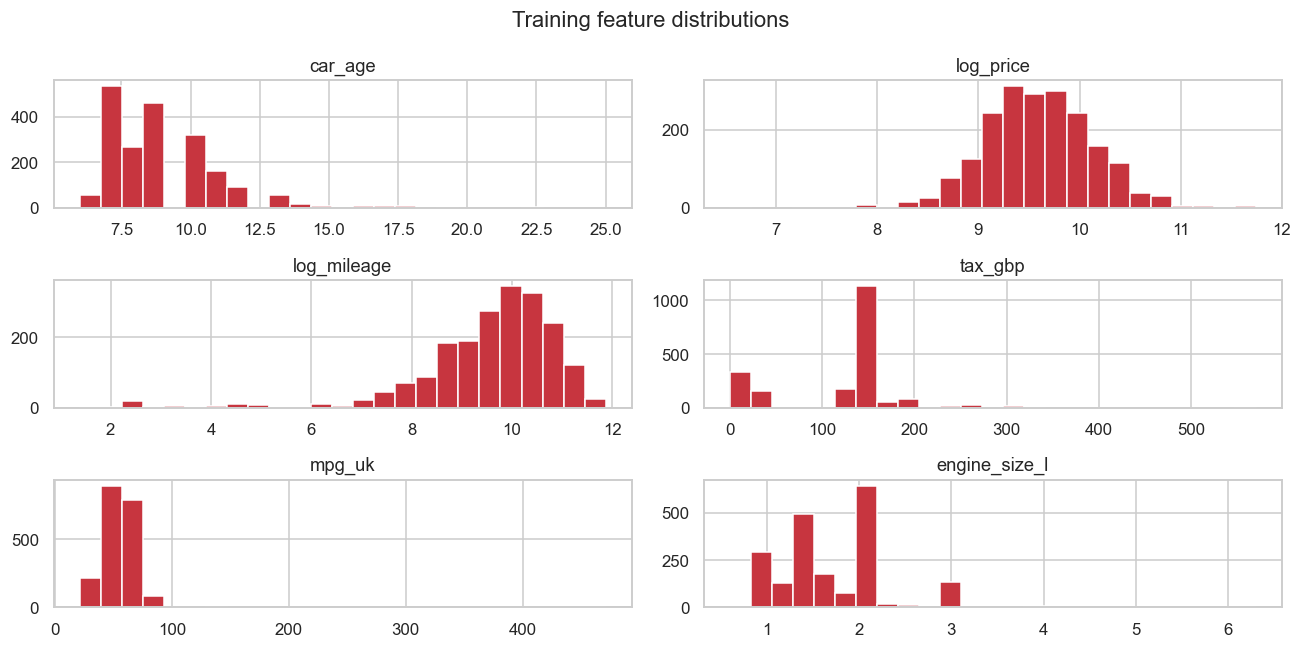

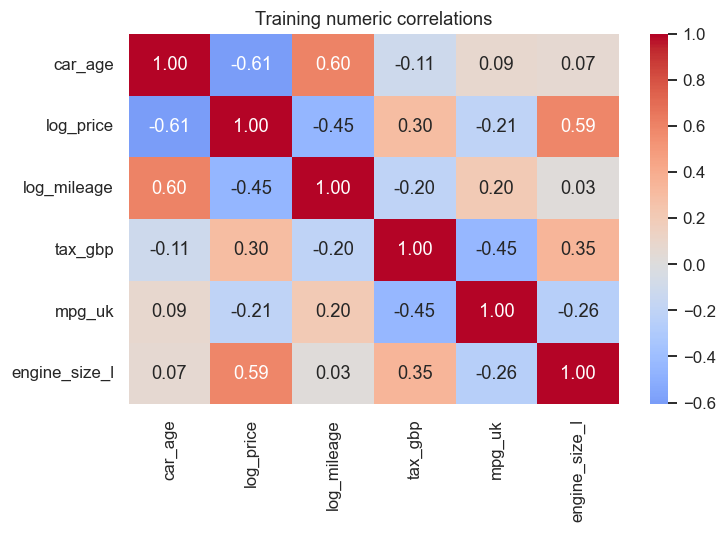

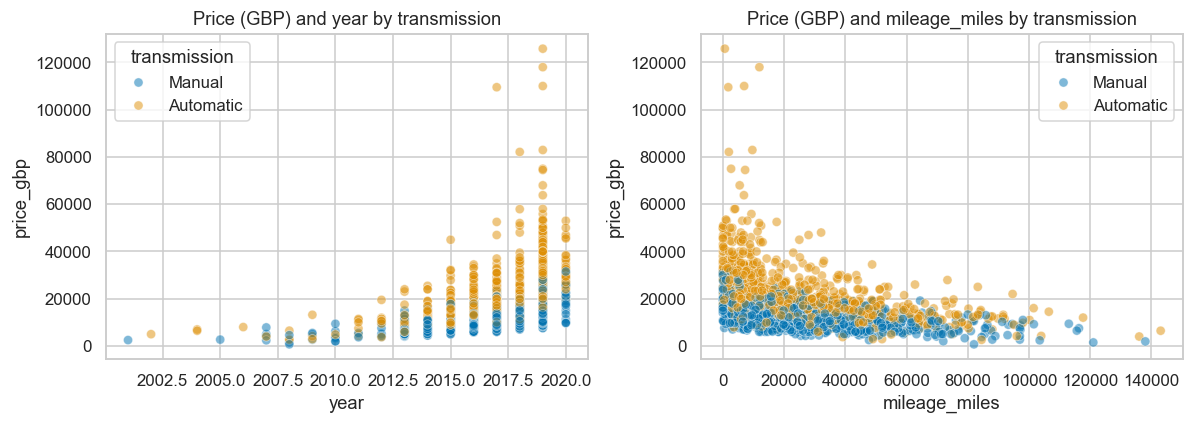

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,2000,9,Ford,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,2000,143,Fiesta,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2016.9735,2.129569,2001.0,2016.0,2017.0,2019.0,2020.0
price_gbp,2000.0,NaN,NaN,NaN,17001.7955,10392.673128,694.0,10417.25,14492.0,20900.0,125796.0
mileage_miles,2000.0,NaN,NaN,NaN,24529.251,21740.610165,3.0,8121.75,18820.0,34000.0,143000.0
fuel_type,2000,4,Petrol,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax_gbp,2000.0,NaN,NaN,NaN,120.4075,67.327468,0.0,125.0,145.0,145.0,570.0
mpg_uk,2000.0,NaN,NaN,NaN,55.725,17.138348,21.4,46.3,55.4,63.15,470.8
engine_size_l,2000.0,NaN,NaN,NaN,1.7235,0.577472,0.6,1.4,1.6,2.0,6.3
transmission,2000,2,Manual,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


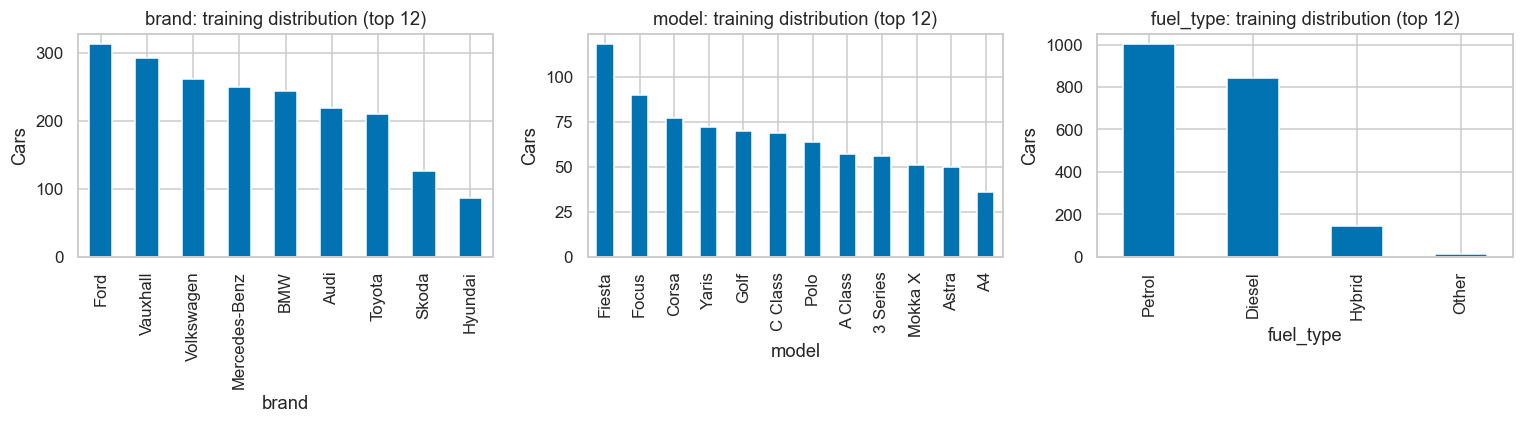

In [3]:
audit_plots(df, train)
display(train.describe(include="all").T)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
engineered_train = CarFeatures().transform(X_train)
for axis, column in zip(axes.ravel(), ["brand", "model", "fuel_type"]):
    engineered_train[column].value_counts().head(12).plot.bar(ax=axis)
    axis.set(
        title=f"{column}: training distribution (top 12)",
        xlabel=column,
        ylabel="Cars",
    )
plt.tight_layout()
plt.show()


## 4. Model training and tuning

Part A is intentionally a baseline rerun, so no hyperparameter search is performed. The complete pipeline is still evaluated with five-fold stratified cross-validation.

In [4]:
slug = "knn"
name, estimator = part_a_models()[slug]
model = build_pipeline(clone(estimator))

print("Baseline estimator:")
display(estimator)
print("No parameter grid: this is the comparable Part A baseline rerun.")

Baseline estimator:
No parameter grid: this is the comparable Part A baseline rerun.


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [5]:
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    cv_result = cross_validate(
        model,
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    model.fit(X_train, y_train)

warning_messages = sorted({str(item.message) for item in captured})
display(pd.DataFrame({key: value for key, value in cv_result.items() if key.startswith("test_")}))
print("Mean training CV macro F1:", cv_result["test_f1_macro"].mean())
print("Recorded training warnings:", warning_messages or "None")

Mean training CV macro F1: 0.8263767255763549
Recorded training warnings: None


,test_f1_macro,test_f1_weighted,test_balanced_accuracy
0,0.859986,0.859986,0.8600
1,0.834983,0.834983,0.8350
2,0.797042,0.797042,0.7975
3,0.824891,0.824891,0.8250
4,0.814981,0.814981,0.8150


## 5. Evaluation

In [6]:
result = pd.DataFrame(
    [
        {
            "Slug": slug,
            "Model": name,
            "Part": "A rerun",
            "Stage": "Baseline",
            **metrics(model, X_test, y_test),
            "CV_macro_F1": float(cv_result["test_f1_macro"].mean()),
            "CV_macro_F1_std": float(cv_result["test_f1_macro"].std()),
        }
    ]
)
display(result.round(4))
display(
    pd.DataFrame(
        classification_report(
            y_test,
            model.predict(X_test),
            output_dict=True,
            zero_division=0,
        )
    ).T.round(4)
)

output_dir = ROOT / "results" / slug
output_dir.mkdir(parents=True, exist_ok=True)
result.to_csv(output_dir / "comparison.csv", index=False)
pd.DataFrame(
    {key: value for key, value in cv_result.items() if key.startswith("test_")}
).to_csv(output_dir / "baseline_cv_folds.csv", index=False)
pd.DataFrame(
    classification_report(
        y_test,
        model.predict(X_test),
        output_dict=True,
        zero_division=0,
    )
).T.to_csv(output_dir / "before_class_report.csv")
joblib.dump(model, ROOT / "models" / f"{slug}_before.joblib", compress=3)

metadata = {
    "selection_metric": "Five-fold training CV macro F1 (evaluation only; no Part A tuning)",
    "positive_class": "Automatic",
    "warnings": warning_messages,
    "test_used_for_tuning": False,
}
(output_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2, default=str), encoding="utf-8"
)

Out[6]: 178


,Slug,Model,Part,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,knn,KNN,A rerun,Baseline,0.818,0.8195,0.818,0.8178,0.8178,0.818,0.8412,0.784,0.8924,0.8768,0.8264,0.021


,precision,recall,f1-score,support
Automatic,0.8412,0.784,0.8116,250.000
Manual,0.7978,0.852,0.8240,250.000
accuracy,0.8180,0.818,0.8180,0.818
macro avg,0.8195,0.818,0.8178,500.000
weighted avg,0.8195,0.818,0.8178,500.000


## 6. Confusion matrix and model interpretation

This estimator does not expose direct coefficients or feature importances.


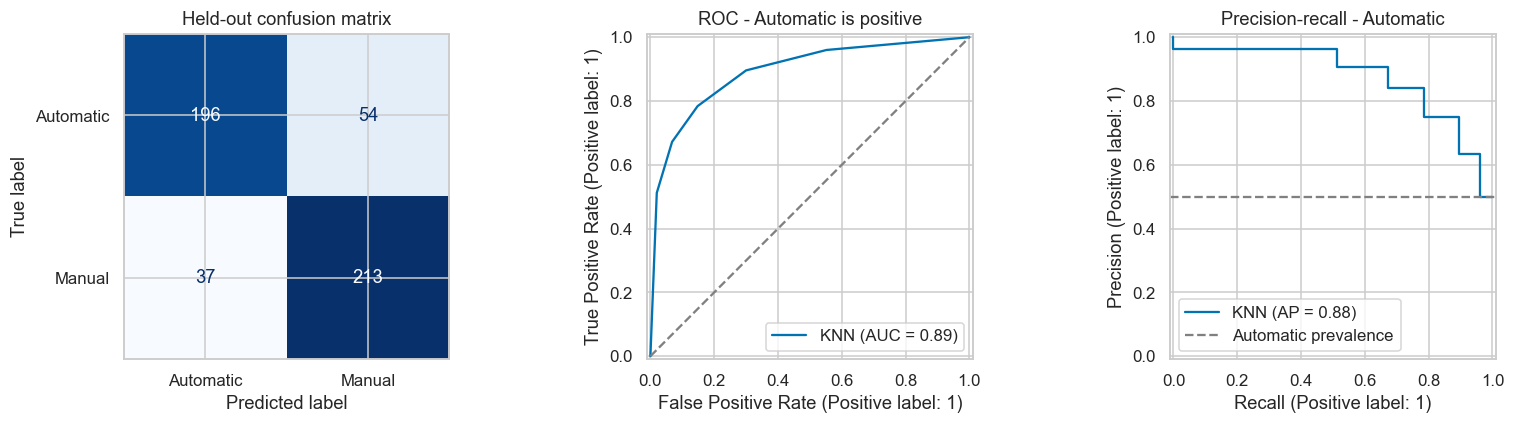

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    labels=["Automatic", "Manual"],
    display_labels=["Automatic", "Manual"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Held-out confusion matrix")

automatic_scores = automatic_probability(model, X_test)
automatic_target = (y_test == "Automatic").astype(int)
RocCurveDisplay.from_predictions(
    automatic_target, automatic_scores, name=name, ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC - Automatic is positive")

PrecisionRecallDisplay.from_predictions(
    automatic_target, automatic_scores, name=name, ax=axes[2]
)
axes[2].axhline(
    automatic_target.mean(), linestyle="--", color="gray", label="Automatic prevalence"
)
axes[2].legend()
axes[2].set_title("Precision-recall - Automatic")
plt.tight_layout()
plt.show()

fitted_estimator = model.named_steps["model"]
feature_names = model.named_steps["preprocess"].get_feature_names_out()
if hasattr(fitted_estimator, "feature_importances_"):
    importance = pd.Series(
        fitted_estimator.feature_importances_, index=feature_names
    ).nlargest(15).sort_values()
    importance.plot.barh(figsize=(8, 5), color="#128276")
    plt.title("Top feature importances")
    plt.xlabel("Impurity-based importance")
    plt.tight_layout()
    plt.show()
elif hasattr(fitted_estimator, "coef_"):
    coefficients = pd.Series(fitted_estimator.coef_[0], index=feature_names)
    strongest = coefficients.loc[
        coefficients.abs().nlargest(15).index
    ].sort_values()
    strongest.plot.barh(figsize=(8, 5), color="#128276")
    plt.title("Strongest signed coefficients")
    plt.xlabel("Coefficient")
    plt.tight_layout()
    plt.show()
else:
    print("This estimator does not expose direct coefficients or feature importances.")

## 7. Observation / Interpretation

**Observation:** This notebook uses **K-Nearest Neighbors Classifier** to predict `transmission`
(Automatic or Manual) from the available car features.

- Cleaning, feature engineering and the fixed split are shared by all ten classifiers.
- Numeric and categorical preprocessing is fitted inside each training fold to avoid leakage.
- Five-fold macro F1 evaluates the Part A baseline; the held-out test set is used only for final reporting.
- Accuracy, weighted precision/recall/F1, macro F1, balanced accuracy, ROC-AUC and the confusion matrix are reported.
- **Model-specific observation:** KNN predicts from nearby training examples, so scaling is essential because feature distances determine the neighbors.

**Team task:** Discuss the actual metric values, class-specific errors and limitations visible in the executed output. Do not assume a performance value that is not displayed.